# PharmaPulse: Pharmaceutical Sales Analytics

## Description
PharmaPulse is a data analytics project built with Databricks, PySpark, and Python to explore historical pharmaceutical sales data. The project analyzes sales trends across time, compares medicine category performance, calculates key performance indicators (KPIs), and identifies patterns in recorded sales. The results are presented through data visualizations and a Databricks dashboard to communicate meaningful business insights.

## Workflow
1. **Data Loading:** Load daily, hourly, weekly, and monthly pharmaceutical sales datasets from Databricks tables.
2. **Data Exploration and Quality Checks:** Inspect schemas, record counts, missing values, and data coverage.
3. **Data Preparation:** Calculate total recorded sales across the eight medicine categories and prepare the data for analysis.
4. **Exploratory Data Analysis:** Examine hourly patterns, monthly trends, annual performance, and medicine category contributions.
5. **Performance Analysis:** Calculate KPIs, year-over-year growth, and category-level sales percentages.
6. **Data Visualization:** Create charts to communicate sales trends, growth or decline, and category comparisons.
7. **Dashboard Development:** Build a Databricks dashboard using the analytical results.
8. **Insights and Recommendations:** Summarize key findings, identify areas for further investigation, and document data limitations.

# Load the Dataset

In [0]:


# Load the four pharmacy sales tables

sales_daily = spark.table("workspace.default.salesdaily")
sales_hourly = spark.table("workspace.default.saleshourly")
sales_monthly = spark.table("workspace.default.salesmonthly")
sales_weekly = spark.table("workspace.default.salesweekly")

# Check the number of rows in each table
print("Daily sales:", sales_daily.count(), "rows")
print("Hourly sales:", sales_hourly.count(), "rows")
print("Monthly sales:", sales_monthly.count(), "rows")
print("Weekly sales:", sales_weekly.count(), "rows")



Daily sales: 2106 rows
Hourly sales: 50532 rows
Monthly sales: 70 rows
Weekly sales: 302 rows


# Schema Inspection and Data Quality Checks

In [0]:
# inspecting my Data 


# Inspect the columns and data types
sales_daily.printSchema()
sales_weekly.printSchema()
sales_monthly.printSchema()
sales_hourly.printSchema()

# Display the first five records
display(sales_daily.limit(5))
display(sales_weekly.limit(5))
display(sales_monthly.limit(5))
display(sales_hourly.limit(5))
# sales_daily
# sales_hourly
# sales_monthly
# sales_weekly




root
 |-- datum: date (nullable = true)
 |-- M01AB: double (nullable = true)
 |-- M01AE: double (nullable = true)
 |-- N02BA: double (nullable = true)
 |-- N02BE: double (nullable = true)
 |-- N05B: double (nullable = true)
 |-- N05C: double (nullable = true)
 |-- R03: double (nullable = true)
 |-- R06: double (nullable = true)
 |-- Year: long (nullable = true)
 |-- Month: long (nullable = true)
 |-- Hour: long (nullable = true)
 |-- Weekday Name: string (nullable = true)

root
 |-- datum: date (nullable = true)
 |-- M01AB: double (nullable = true)
 |-- M01AE: double (nullable = true)
 |-- N02BA: double (nullable = true)
 |-- N02BE: double (nullable = true)
 |-- N05B: double (nullable = true)
 |-- N05C: double (nullable = true)
 |-- R03: double (nullable = true)
 |-- R06: double (nullable = true)

root
 |-- datum: date (nullable = true)
 |-- M01AB: double (nullable = true)
 |-- M01AE: double (nullable = true)
 |-- N02BA: double (nullable = true)
 |-- N02BE: double (nullable = true)
 |-

datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
2014-01-02,0.0,3.67,3.4,32.4,7.0,0.0,0.0,2.0,2014,1,248,Thursday
2014-01-03,8.0,4.0,4.4,50.6,16.0,0.0,20.0,4.0,2014,1,276,Friday
2014-01-04,2.0,1.0,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
2014-01-05,4.0,3.0,7.0,41.1,8.0,0.0,3.0,0.0,2014,1,276,Sunday
2014-01-06,5.0,1.0,4.5,21.7,16.0,2.0,6.0,2.0,2014,1,276,Monday


datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
2014-01-05,14.0,11.67,21.3,185.95,41.0,0.0,32.0,7.0
2014-01-12,29.33,12.68,37.9,190.7,88.0,5.0,21.0,7.2
2014-01-19,30.67,26.34,45.9,218.4,80.0,8.0,29.0,12.0
2014-01-26,34.0,32.37,31.5,179.6,80.0,8.0,23.0,10.0
2014-02-02,31.02,23.35,20.7,159.88,84.0,12.0,29.0,12.0


datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
2014-01-31,127.69000000000001,99.09000000000005,152.09999999999997,878.0300000000002,354.0,50.0,112.0,48.2
2014-02-28,133.32,126.0500000000001,176.99999999999997,1001.9000000000001,347.0,31.0,122.0,36.2
2014-03-31,137.44000000000005,92.95000000000007,147.655,779.275,232.0,20.0,112.0,85.4
2014-04-30,113.10000000000004,89.47500000000008,130.89999999999998,698.5,209.0,18.0,97.0,73.7
2014-05-31,101.79000000000005,119.93300000000009,132.1,628.7800000000001,270.0,23.0,107.0,123.69999999999999


datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
1/2/2014 8:00,0.0,0.67,0.4,2.0,0.0,0.0,0.0,1.0,2014,1,8,Thursday
1/2/2014 9:00,0.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,2014,1,9,Thursday
1/2/2014 10:00,0.0,0.0,0.0,3.0,2.0,0.0,0.0,0.0,2014,1,10,Thursday
1/2/2014 11:00,0.0,0.0,0.0,2.0,1.0,0.0,0.0,0.0,2014,1,11,Thursday
1/2/2014 12:00,0.0,2.0,0.0,5.0,2.0,0.0,0.0,0.0,2014,1,12,Thursday


In [0]:

from pyspark.sql import functions as F

# Step 1: Check the size of each dataset
datasets = {
    "Daily": sales_daily,
    "Weekly": sales_weekly,
    "Monthly": sales_monthly,
    "Hourly": sales_hourly
}

for name, df in datasets.items():
    print(f"{name} sales - Rows: {df.count()}, Columns: {len(df.columns)}")


# Step 2: Create a function to check missing values
def check_missing_values(df, dataset_name):
    print(f"\nMissing values in {dataset_name} sales:")

    missing_values = df.select([
        F.sum(
            F.when(F.col(c).isNull(), 1).otherwise(0)
        ).alias(c)
        for c in df.columns
    ])

    display(missing_values)


# Step 3: Check each dataset
check_missing_values(sales_daily, "Daily")
check_missing_values(sales_weekly, "Weekly")
check_missing_values(sales_monthly, "Monthly")
check_missing_values(sales_hourly, "Hourly")


Daily sales - Rows: 2106, Columns: 13
Weekly sales - Rows: 302, Columns: 9
Monthly sales - Rows: 70, Columns: 9
Hourly sales - Rows: 50532, Columns: 13

Missing values in Daily sales:


datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,0,0,0,0,0,0,0,0,0,0,0,0



Missing values in Weekly sales:


datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,0,0,0,0,0,0,0,0



Missing values in Monthly sales:


datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,0,0,0,0,0,0,0,0



Missing values in Hourly sales:


datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,0,0,0,0,0,0,0,0,0,0,0,0


In [0]:
# inspect what inside the data 


datasets = {
    "Hourly": sales_hourly,
    "Daily": sales_daily,
    "Weekly": sales_weekly,
    "Monthly": sales_monthly
}

for name, df in datasets.items():
    print(f"\n{'=' * 15} {name.upper()} SALES {'=' * 15}")

    df.printSchema()

    display(df.limit(5))



=============== HOURLY SALES ===============
root
 |-- datum: string (nullable = true)
 |-- M01AB: double (nullable = true)
 |-- M01AE: double (nullable = true)
 |-- N02BA: double (nullable = true)
 |-- N02BE: double (nullable = true)
 |-- N05B: double (nullable = true)
 |-- N05C: double (nullable = true)
 |-- R03: double (nullable = true)
 |-- R06: double (nullable = true)
 |-- Year: long (nullable = true)
 |-- Month: long (nullable = true)
 |-- Hour: long (nullable = true)
 |-- Weekday Name: string (nullable = true)



datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
1/2/2014 8:00,0.0,0.67,0.4,2.0,0.0,0.0,0.0,1.0,2014,1,8,Thursday
1/2/2014 9:00,0.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,2014,1,9,Thursday
1/2/2014 10:00,0.0,0.0,0.0,3.0,2.0,0.0,0.0,0.0,2014,1,10,Thursday
1/2/2014 11:00,0.0,0.0,0.0,2.0,1.0,0.0,0.0,0.0,2014,1,11,Thursday
1/2/2014 12:00,0.0,2.0,0.0,5.0,2.0,0.0,0.0,0.0,2014,1,12,Thursday



=============== DAILY SALES ===============
root
 |-- datum: date (nullable = true)
 |-- M01AB: double (nullable = true)
 |-- M01AE: double (nullable = true)
 |-- N02BA: double (nullable = true)
 |-- N02BE: double (nullable = true)
 |-- N05B: double (nullable = true)
 |-- N05C: double (nullable = true)
 |-- R03: double (nullable = true)
 |-- R06: double (nullable = true)
 |-- Year: long (nullable = true)
 |-- Month: long (nullable = true)
 |-- Hour: long (nullable = true)
 |-- Weekday Name: string (nullable = true)



datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
2014-01-02,0.0,3.67,3.4,32.4,7.0,0.0,0.0,2.0,2014,1,248,Thursday
2014-01-03,8.0,4.0,4.4,50.6,16.0,0.0,20.0,4.0,2014,1,276,Friday
2014-01-04,2.0,1.0,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
2014-01-05,4.0,3.0,7.0,41.1,8.0,0.0,3.0,0.0,2014,1,276,Sunday
2014-01-06,5.0,1.0,4.5,21.7,16.0,2.0,6.0,2.0,2014,1,276,Monday



=============== WEEKLY SALES ===============
root
 |-- datum: date (nullable = true)
 |-- M01AB: double (nullable = true)
 |-- M01AE: double (nullable = true)
 |-- N02BA: double (nullable = true)
 |-- N02BE: double (nullable = true)
 |-- N05B: double (nullable = true)
 |-- N05C: double (nullable = true)
 |-- R03: double (nullable = true)
 |-- R06: double (nullable = true)



datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
2014-01-05,14.0,11.67,21.3,185.95,41.0,0.0,32.0,7.0
2014-01-12,29.33,12.68,37.9,190.7,88.0,5.0,21.0,7.2
2014-01-19,30.67,26.34,45.9,218.4,80.0,8.0,29.0,12.0
2014-01-26,34.0,32.37,31.5,179.6,80.0,8.0,23.0,10.0
2014-02-02,31.02,23.35,20.7,159.88,84.0,12.0,29.0,12.0



=============== MONTHLY SALES ===============
root
 |-- datum: date (nullable = true)
 |-- M01AB: double (nullable = true)
 |-- M01AE: double (nullable = true)
 |-- N02BA: double (nullable = true)
 |-- N02BE: double (nullable = true)
 |-- N05B: double (nullable = true)
 |-- N05C: double (nullable = true)
 |-- R03: double (nullable = true)
 |-- R06: double (nullable = true)



datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
2014-01-31,127.69000000000001,99.09000000000005,152.09999999999997,878.0300000000002,354.0,50.0,112.0,48.2
2014-02-28,133.32,126.0500000000001,176.99999999999997,1001.9000000000001,347.0,31.0,122.0,36.2
2014-03-31,137.44000000000005,92.95000000000007,147.655,779.275,232.0,20.0,112.0,85.4
2014-04-30,113.10000000000004,89.47500000000008,130.89999999999998,698.5,209.0,18.0,97.0,73.7
2014-05-31,101.79000000000005,119.93300000000009,132.1,628.7800000000001,270.0,23.0,107.0,123.69999999999999


## Exploratory Data Analysis

In [0]:

# summarize the hourly sales
from pyspark.sql import functions as F

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

sales_summary = sales_hourly.agg(
    *[
        F.round(F.sum(F.col(c)), 0).alias(c)
        for c in medicine_columns
    ]
)

display(sales_summary)


M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
10601.0,8205.0,8172.0,63005.0,18646.0,1250.0,11609.0,6108.0


In [0]:

# Convert the summary into a category-by-category table
sales_long = sales_summary.select(
    F.explode(
        F.array(*[
            F.struct(
                F.lit(c).alias("Medicine_Category"),
                F.col(c).alias("Total_Sales")
            )
            for c in medicine_columns
        ])
    ).alias("sales")
).select("sales.*")

display(
    sales_long.orderBy(F.col("Total_Sales").desc())
)


In [0]:

# Summarize hourly sales by average and total
from pyspark.sql import functions as F

# Medicine category columns
medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Calculate total sales across all medicine categories for each record
total_sales_expression = sum(
    F.coalesce(F.col(c).cast("double"), F.lit(0.0))
    for c in medicine_columns
)

sales_with_total = sales_hourly.withColumn(
    "Total_Sales",
    total_sales_expression
)

# Summarize sales by hour
hourly_pattern = (
    sales_with_total
    .groupBy("Hour")
    .agg(
        F.round(F.sum("Total_Sales"), 0).alias("Total_Sales"),
        F.round(F.avg("Total_Sales"), 2).alias("Average_Sales"),
        F.count("*").alias("Observations")
    )
    .orderBy("Hour")
)

display(hourly_pattern)


Hour,Total_Sales,Average_Sales,Observations
0,0.0,0.0,2105
1,0.0,0.0,2105
2,0.0,0.0,2105
3,0.0,0.0,2105
4,0.0,0.0,2105
5,0.0,0.0,2105
6,0.0,0.0,2105
7,573.0,0.27,2105
8,6041.0,2.87,2106
9,8095.0,3.84,2106


In [0]:

from pyspark.sql import functions as F

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

total_sales_expression = sum(
    F.coalesce(F.col(c).cast("double"), F.lit(0.0))
    for c in medicine_columns
)

# Check whether all eight medicine columns are missing
all_null_condition = F.col(medicine_columns[0]).isNull()

for c in medicine_columns[1:]:
    all_null_condition = all_null_condition & F.col(c).isNull()

diagnostic = (
    sales_hourly
    .withColumn("Row_Total", total_sales_expression)
    .groupBy("Hour")
    .agg(
        F.count("*").alias("Total_Rows"),
        F.sum(
            F.when(F.col("Row_Total") > 0, 1).otherwise(0)
        ).alias("Rows_With_Sales"),
        F.sum(
            F.when(F.col("Row_Total") == 0, 1).otherwise(0)
        ).alias("Rows_With_Zero_Total"),
        F.sum(
            F.when(all_null_condition, 1).otherwise(0)
        ).alias("Rows_All_Medicine_Values_Missing")
    )
    .orderBy("Hour")
)

display(diagnostic)


Hour,Total_Rows,Rows_With_Sales,Rows_With_Zero_Total,Rows_All_Medicine_Values_Missing
0,2105,0,2105,0
1,2105,0,2105,0
2,2105,0,2105,0
3,2105,0,2105,0
4,2105,0,2105,0
5,2105,0,2105,0
6,2105,0,2105,0
7,2105,315,1790,0
8,2106,1749,357,0
9,2106,1898,208,0


In [0]:
 # Investigate hourly sales by examining records from selected hours (00:00, 08:00, 19:00, and 23:00).
# Display the timestamp and all eight medicine categories to compare sales across different dates.
# Sort the records chronologically by date and hour, and display the first 30 rows.

from pyspark.sql import functions as F

display(
    sales_hourly
    .filter(F.col("Hour").isin(0, 8, 19, 23))
    .select(
        "datum",
        "Hour",
        "M01AB", "M01AE", "N02BA", "N02BE",
        "N05B", "N05C", "R03", "R06"
    )
    .orderBy("datum", "Hour")
    .limit(30)
)


datum,Hour,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
1/1/2015 0:00,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1/1/2015 19:00,19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1/1/2015 23:00,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1/1/2015 8:00,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1/1/2016 0:00,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1/1/2016 19:00,19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1/1/2016 23:00,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1/1/2016 8:00,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1/1/2017 0:00,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1/1/2017 19:00,19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [0]:

# Check how many distinct dates have positive sales or zero sales at each hour.
# This helps us determine whether the zero-sales pattern is consistent across the dataset.

from pyspark.sql import functions as F

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Calculate combined sales across all eight medicine categories per record.
total_sales_expression = sum(
    F.coalesce(F.col(c).cast("double"), F.lit(0.0))
    for c in medicine_columns
)

timestamp_sales = sales_hourly.withColumn(
    "Total_Sales",
    total_sales_expression
)

# Count distinct dates with positive sales and zero sales for each hour.
date_pattern = (
    timestamp_sales
    .groupBy("Hour")
    .agg(
        F.countDistinct(
            F.when(
                F.col("Total_Sales") > 0,
                F.to_date("datum", "M/d/yyyy H:mm")
            )
        ).alias("Dates_With_Sales"),
        F.countDistinct(
            F.when(
                F.col("Total_Sales") == 0,
                F.to_date("datum", "M/d/yyyy H:mm")
            )
        ).alias("Dates_With_Zero_Sales")
    )
    .orderBy("Hour")
)

display(date_pattern)


Hour,Dates_With_Sales,Dates_With_Zero_Sales
0,0,2105
1,0,2105
2,0,2105
3,0,2105
4,0,2105
5,0,2105
6,0,2105
7,315,1790
8,1749,357
9,1898,208


The dataset has a pronounced hourly sales pattern, with no recorded sales overnight and substantially more sales activity during daytime and early evening hours.

In [0]:

# Analyze monthly sales trends by combining the eight medicine categories.
# Group records by year and month to compare sales volume over time.

from pyspark.sql import functions as F

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Calculate total sales across all medicine categories for each record.
total_sales_expression = sum(
    F.coalesce(F.col(c).cast("double"), F.lit(0.0))
    for c in medicine_columns
)

monthly_trends = (
    sales_hourly
    .withColumn("Total_Sales", total_sales_expression)
    .withColumn(
        "Parsed_Date",
        F.to_timestamp("datum", "M/d/yyyy H:mm")
    )
    .withColumn("Year", F.year("Parsed_Date"))
    .withColumn("Month", F.month("Parsed_Date"))
    .groupBy("Year", "Month")
    .agg(
        F.round(F.sum("Total_Sales"), 2).alias("Total_Sales"),
        F.count("*").alias("Observations")
    )
    .orderBy("Year", "Month")
)

display(monthly_trends)


Year,Month,Total_Sales,Observations
2014,1,1801.11,712
2014,2,1974.47,672
2014,3,1606.72,744
2014,4,1423.92,720
2014,5,1506.3,744
2014,6,1390.2,720
2014,7,1332.37,744
2014,8,1452.52,744
2014,9,1804.59,720
2014,10,2082.0,744


The monthly sales analysis shows that total medicine sales fluctuate over time, with noticeable differences between years and months. In 2014, monthly sales ranged from approximately 1,332 in July to 2,093 in December. Sales generally increased during 2015 and 2016, reaching 2,655 in October 2016. In 2017, sales declined considerably, particularly from February through August, before recovering toward the end of the year. Sales increased again in 2018, with October and December recording approximately 2,195 and 2,248, respectively. In 2019, January recorded the highest monthly sales in the displayed period, at 2,875, followed by fluctuations throughout the year. However, October 2019 contains only 188 observations, compared with approximately 720–744 observations in most complete months, and its total sales of 538.60 should therefore not be directly compared with those of complete months. The results suggest possible temporal trends and seasonal variation, but further analysis is needed before drawing firm conclusions about seasonality or long-term growth.

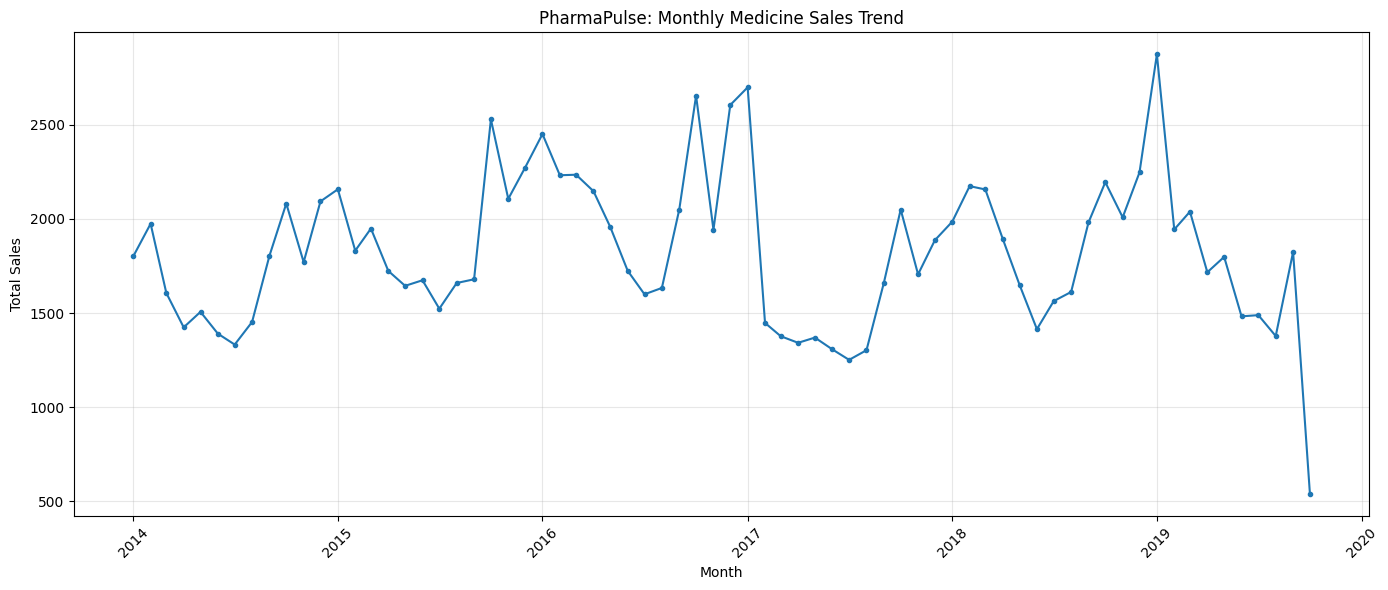

In [0]:

# Visualize monthly medicine sales over time to identify trends,
# fluctuations, and potentially unusual changes in sales volume.

import matplotlib.pyplot as plt
import pandas as pd

# Convert the Spark DataFrame to Pandas for plotting.
monthly_pd = monthly_trends.toPandas()

# Create a proper date column for chronological plotting.
monthly_pd["Date"] = pd.to_datetime(
    monthly_pd[["Year", "Month"]].assign(Day=1)
)

# Plot the monthly sales trend.
plt.figure(figsize=(14, 6))
plt.plot(
    monthly_pd["Date"],
    monthly_pd["Total_Sales"],
    marker="o",
    markersize=3
)

plt.title("PharmaPulse: Monthly Medicine Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [0]:
# calculateing the annual sales and year over year changes
# Compare annual medicine sales and calculate year-over-year percentage changes.
# Count available months to identify incomplete years before interpreting the results.

from pyspark.sql import functions as F
from pyspark.sql.window import Window

annual_sales = (
    monthly_trends
    .groupBy("Year")
    .agg(
        F.round(F.sum("Total_Sales"), 2).alias("Annual_Sales"),
        F.countDistinct("Month").alias("Months_Available"),
        F.sum("Observations").alias("Total_Observations")
    )
)

# Compare each year with the previous year.
year_window = Window.orderBy("Year")

annual_comparison = (
    annual_sales
    .withColumn(
        "Previous_Year_Sales",
        F.lag("Annual_Sales").over(year_window)
    )
    .withColumn(
        "YoY_Change_Percent",
        F.round(
            (
                (F.col("Annual_Sales") - F.col("Previous_Year_Sales"))
                / F.col("Previous_Year_Sales")
            ) * 100,
            2
        )
    )
    .orderBy("Year")
)

display(annual_comparison)


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Year,Annual_Sales,Months_Available,Total_Observations,Previous_Year_Sales,YoY_Change_Percent
2014,20238.33,12,8728,null,null
2015,22752.37,12,8760,20238.33,12.42
2016,25234.93,12,8784,22752.37,10.91
2017,19399.38,12,8760,25234.93,-23.12
2018,22884.56,12,8760,19399.38,17.97
2019,17085.96,10,6740,22884.56,-25.34


In [0]:

# Compare each month's sales with the same month in the previous year.
# Calculate year-over-year percentage change to identify growth and decline
# while controlling for differences between months.

from pyspark.sql import functions as F
from pyspark.sql.window import Window

monthly_window = Window.partitionBy("Month").orderBy("Year")

monthly_yoy = (
    monthly_trends
    .withColumn(
        "Previous_Year_Sales",
        F.lag("Total_Sales").over(monthly_window)
    )
    .withColumn(
        "YoY_Change_Percent",
        F.round(
            (
                (F.col("Total_Sales") - F.col("Previous_Year_Sales"))
                / F.col("Previous_Year_Sales")
            ) * 100,
            2
        )
    )
    .orderBy("Year", "Month")
)

display(monthly_yoy)


Year,Month,Total_Sales,Observations,Previous_Year_Sales,YoY_Change_Percent
2014,1,1801.11,712,null,null
2014,2,1974.47,672,null,null
2014,3,1606.72,744,null,null
2014,4,1423.92,720,null,null
2014,5,1506.3,744,null,null
2014,6,1390.2,720,null,null
2014,7,1332.37,744,null,null
2014,8,1452.52,744,null,null
2014,9,1804.59,720,null,null
2014,10,2082.0,744,null,null


In [0]:

# Identify the strongest and weakest year-over-year sales changes.
# Exclude October 2019 because its observation count indicates incomplete monthly coverage.

comparable_yoy = monthly_yoy.filter(
    ~((F.col("Year") == 2019) & (F.col("Month") == 10))
)

print("Top 10 monthly year-over-year increases")
display(
    comparable_yoy
    .filter(F.col("YoY_Change_Percent").isNotNull())
    .orderBy(F.col("YoY_Change_Percent").desc())
    .limit(10)
)

print("Top 10 monthly year-over-year decreases")
display(
    comparable_yoy
    .filter(F.col("YoY_Change_Percent").isNotNull())
    .orderBy(F.col("YoY_Change_Percent").asc())
    .limit(10)
)


Top 10 monthly year-over-year increases


Year,Month,Total_Sales,Observations,Previous_Year_Sales,YoY_Change_Percent
2018,3,2156.85,744,1376.86,56.65
2018,2,2174.5,672,1447.47,50.23
2019,1,2875.16,744,1985.7,44.79
2018,4,1894.73,720,1341.8,41.21
2018,7,1563.48,744,1251.15,24.96
2016,4,2147.57,720,1723.88,24.58
2018,8,1611.91,744,1302.42,23.76
2016,9,2049.88,720,1679.37,22.06
2016,2,2232.4,696,1831.53,21.89
2015,10,2529.58,744,2082.0,21.5


Top 10 monthly year-over-year decreases


Year,Month,Total_Sales,Observations,Previous_Year_Sales,YoY_Change_Percent
2017,3,1376.86,744,2235.17,-38.4
2017,4,1341.8,720,2147.57,-37.52
2017,2,1447.47,672,2232.4,-35.16
2017,5,1369.49,744,1957.02,-30.02
2017,12,1887.1,744,2605.76,-27.58
2018,1,1985.7,744,2699.6,-26.44
2017,6,1306.94,720,1724.73,-24.22
2017,10,2050.13,744,2655.39,-22.79
2017,7,1251.15,744,1599.64,-21.79
2017,8,1302.42,744,1633.39,-20.26


The analysis of the ten strongest year-over-year (YoY) increases shows that March 2018 recorded the highest growth at 56.65%, followed by February 2018 at 50.23% and January 2019 at 44.79%. April 2018 also experienced a substantial increase of 41.21%. These results indicate a strong recovery in sales during several months of 2018 compared with the corresponding months in 2017. However, the largest increases should be interpreted in the context of the unusually low sales recorded during 2017.

In contrast, the sharpest YoY declines occurred in 2017. March recorded the largest decrease at 38.40%, followed by April at 37.52% and February at 35.16%. Sales also declined considerably in May and December 2017, by 30.02% and 27.58%, respectively. January 2018 recorded a further decline of 26.44% compared with January 2017, before sales recovered in February and March. Since these patterns show substantial changes between consecutive years, further investigation is needed to determine whether they reflect genuine demand changes, changes in the data, or other factors. The sales data alone cannot establish the cause.

In [0]:
# Calculate annual sales by medicine category
# Analyze annual sales for each medicine category to compare category-level
# performance over time and identify which categories contribute most to sales.

from pyspark.sql import functions as F

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Extract the year from each timestamp.
sales_by_year = sales_hourly.withColumn(
    "Year",
    F.year(F.to_timestamp("datum", "M/d/yyyy H:mm"))
)

# Sum sales for each medicine category by year.
annual_category_sales = (
    sales_by_year
    .groupBy("Year")
    .agg(*[
        F.round(F.sum(F.col(c)), 2).alias(c)
        for c in medicine_columns
    ])
    .orderBy("Year")
)

display(annual_category_sales)


Year,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
2014,1447.21,1257.1,1616.47,9274.38,4315.06,272.63,1255.0,800.49
2015,1895.62,1496.6,1608.63,11923.22,2965.0,159.0,1721.25,983.03
2016,2107.28,1589.44,1655.22,13335.58,3138.33,207.0,2137.0,1065.07
2017,1846.62,1387.3,1288.3,9258.8,2555.54,180.33,1893.61,988.86
2018,1786.93,1389.66,1123.8,11230.92,3266.2,235.0,2655.25,1196.8
2019,1517.27,1084.52,879.8,7982.49,2405.6,196.0,1946.71,1073.57


the annual category analysis shows that N02BE is the largest contributor to recorded sales in every year. Its sales increased from 9,274.38 in 2014 to a peak of 13,335.58 in 2016, declined to 9,258.80 in 2017, and recovered to 11,230.92 in 2018. M01AB also increased between 2014 and 2016 before declining in subsequent years. N05B experienced a sharp decrease from 4,315.06 in 2014 to 2,965.00 in 2015, followed by fluctuations through 2018. In contrast, R03 generally increased over the period, reaching 2,655.25 in 2018. N02BA declined from 1,616.47 in 2014 to 1,123.80 in 2018, while M01AE showed relatively moderate changes. N05C remained the smallest category by sales volume throughout the period. The 2019 figures are incomplete because the dataset ends in October, so they should not be compared directly with full-year totals. Overall, the results indicate that sales patterns differ considerably by medicine category, making category-level analysis important for understanding changes in total sales.

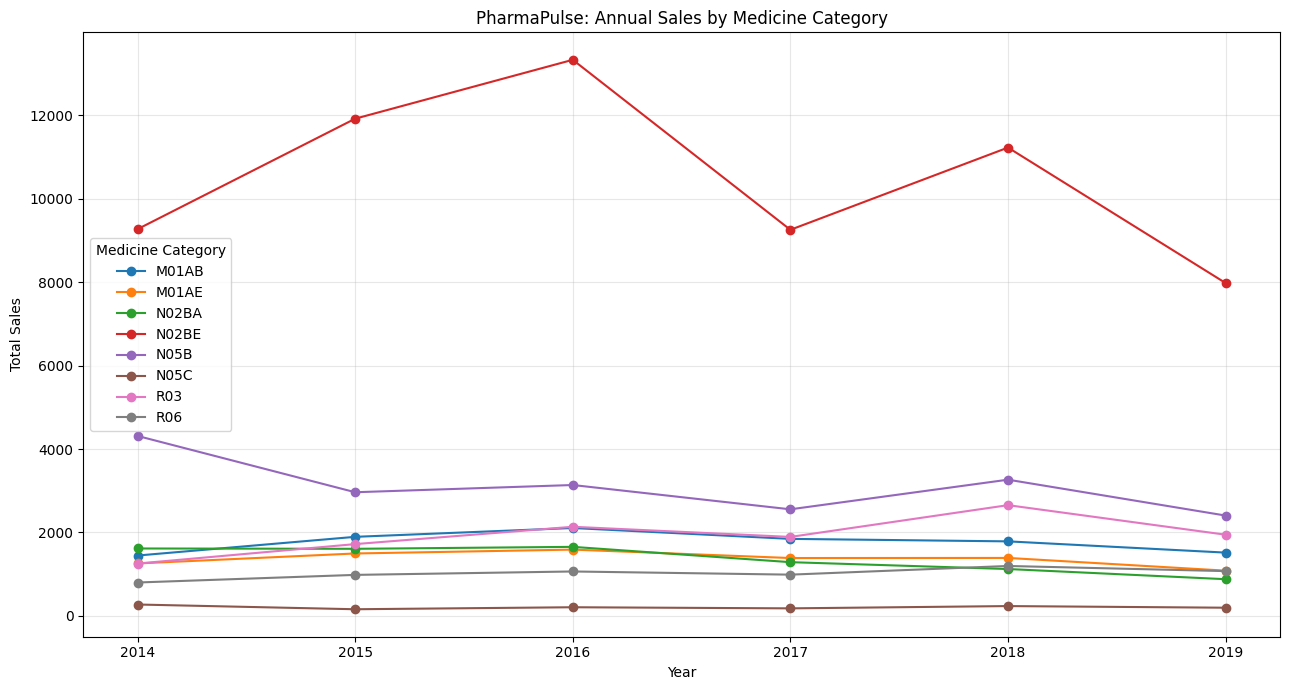

In [0]:
# visualize category trends over time 


# Visualize annual sales trends for all eight medicine categories.
# This helps compare category performance and identify peaks and declines over time.

import matplotlib.pyplot as plt

annual_category_pd = annual_category_sales.toPandas()
annual_category_pd = annual_category_pd.sort_values("Year")

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

plt.figure(figsize=(13, 7))

for category in medicine_columns:
    plt.plot(
        annual_category_pd["Year"],
        annual_category_pd[category],
        marker="o",
        label=category
    )

plt.title("PharmaPulse: Annual Sales by Medicine Category")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(annual_category_pd["Year"])
plt.legend(title="Medicine Category")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [0]:
# Calculate annual sales contribution (%) 
# Calculate each medicine category's share of total annual sales.
# This helps measure category importance without comparing only raw sales values.

from pyspark.sql import functions as F

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Calculate total sales across all medicine categories for each year.
annual_category_share = annual_category_sales.withColumn(
    "Total_Sales",
    sum(F.coalesce(F.col(c), F.lit(0.0)) for c in medicine_columns)
)

# Convert each category's annual sales into a percentage of total sales.
for category in medicine_columns:
    annual_category_share = annual_category_share.withColumn(
        f"{category}_Share_Percent",
        F.round(
            F.col(category) / F.col("Total_Sales") * 100,
            2
        )
    )

# Display the category shares alongside the annual total.
display(
    annual_category_share.select(
        "Year",
        "Total_Sales",
        *[f"{c}_Share_Percent" for c in medicine_columns]
    ).orderBy("Year")
)
 

Year,Total_Sales,M01AB_Share_Percent,M01AE_Share_Percent,N02BA_Share_Percent,N02BE_Share_Percent,N05B_Share_Percent,N05C_Share_Percent,R03_Share_Percent,R06_Share_Percent
2014,20238.340000000004,7.15,6.21,7.99,45.83,21.32,1.35,6.2,3.96
2015,22752.35,8.33,6.58,7.07,52.4,13.03,0.7,7.57,4.32
2016,25234.92,8.35,6.3,6.56,52.85,12.44,0.82,8.47,4.22
2017,19399.360000000004,9.52,7.15,6.64,47.73,13.17,0.93,9.76,5.1
2018,22884.56,7.81,6.07,4.91,49.08,14.27,1.03,11.6,5.23
2019,17085.96,8.88,6.35,5.15,46.72,14.08,1.15,11.39,6.28


In [0]:

# Measure year-over-year sales growth for each medicine category.
# This shows the percentage increase or decrease in category sales compared with the previous year.

from pyspark.sql import functions as F
from pyspark.sql.window import Window

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Compare each year with the preceding year.
year_window = Window.orderBy("Year")

annual_category_growth = annual_category_sales

for category in medicine_columns:
    previous_sales = F.lag(F.col(category)).over(year_window)

    annual_category_growth = annual_category_growth.withColumn(
        f"{category}_YoY_Percent",
        F.round(
            (F.col(category) - previous_sales)
            / previous_sales * 100,
            2
        )
    )

# Display the percentage growth or decline for every category and year.
display(
    annual_category_growth.select(
        "Year",
        *[f"{c}_YoY_Percent" for c in medicine_columns]
    ).orderBy("Year")
)


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Year,M01AB_YoY_Percent,M01AE_YoY_Percent,N02BA_YoY_Percent,N02BE_YoY_Percent,N05B_YoY_Percent,N05C_YoY_Percent,R03_YoY_Percent,R06_YoY_Percent
2014,null,null,null,null,null,null,null,null
2015,30.98,19.05,-0.49,28.56,-31.29,-41.68,37.15,22.8
2016,11.17,6.2,2.9,11.85,5.85,30.19,24.15,8.35
2017,-12.37,-12.72,-22.17,-30.57,-18.57,-12.88,-11.39,-7.16
2018,-3.23,0.17,-12.77,21.3,27.81,30.32,40.22,21.03
2019,-15.09,-21.96,-21.71,-28.92,-26.35,-16.6,-26.68,-10.3


The year-over-year analysis shows that 2015 was a strong growth year for several categories, particularly R03, which increased by 37.15%, M01AB by 30.98%, and N02BE by 28.56%. However, N05B and N05C declined by 31.29% and 41.68%, respectively, indicating that growth was not consistent across all categories. In 2016, most categories continued to grow, with N05C increasing by 30.19% and R03 by 24.15%. The most significant broad decline occurred in 2017, when all eight categories recorded negative year-over-year growth; N02BE fell by 30.57%, while N02BA declined by 22.17%. In 2018, the pattern changed: R03 grew by 40.22%, N05C by 30.32%, N05B by 27.81%, and N02BE by 21.30%, suggesting a recovery across several categories. The displayed 2019 growth rates are negative for all categories, but these figures compare incomplete 2019 data with full-year 2018 totals, so they cannot establish that sales genuinely declined year over year. Overall, the results highlight a broad category-level downturn in 2017 followed by a strong recovery in several categories during 2018, while also showing that different categories followed different growth patterns.

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


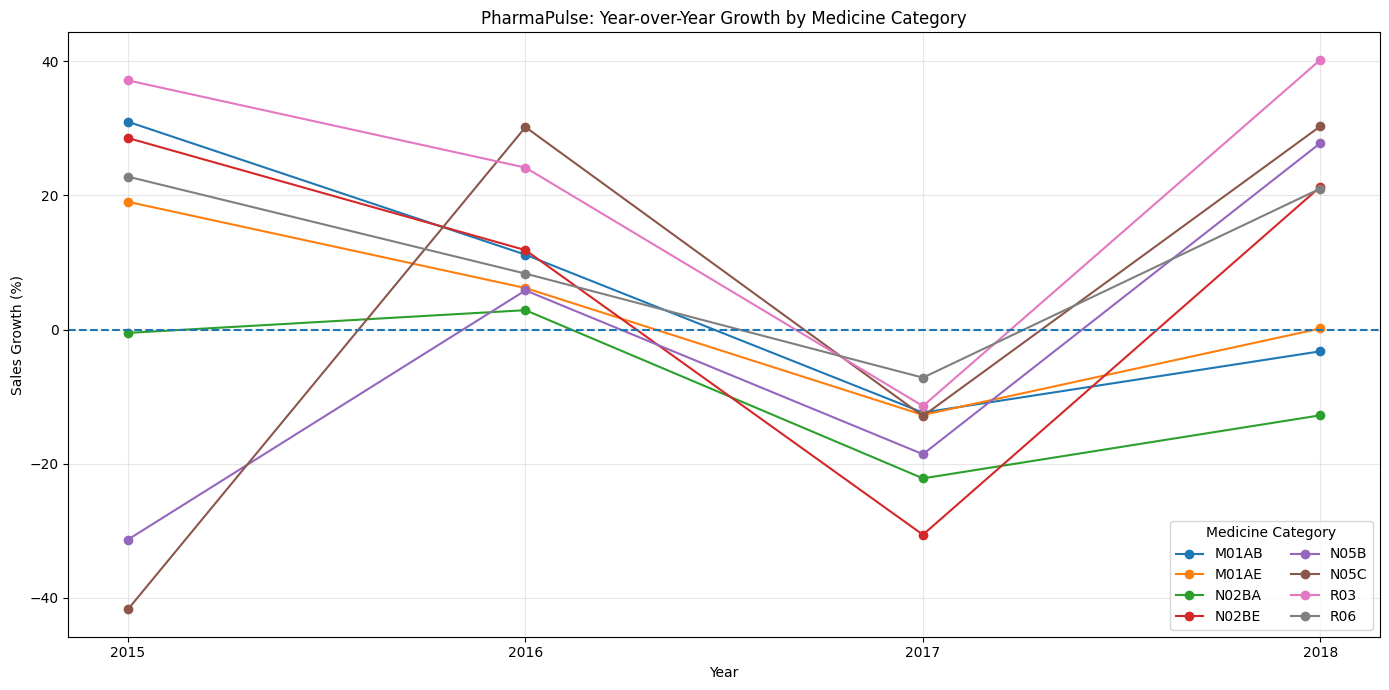

In [0]:

# Visualize year-over-year sales growth for each medicine category.
# We exclude 2019 because the available data covers only part of that year.

import matplotlib.pyplot as plt

growth_columns = [f"{c}_YoY_Percent" for c in medicine_columns]

growth_pd = (
    annual_category_growth
    .filter(F.col("Year").between(2015, 2018))
    .select("Year", *growth_columns)
    .toPandas()
    .sort_values("Year")
)

plt.figure(figsize=(14, 7))

for category in medicine_columns:
    plt.plot(
        growth_pd["Year"],
        growth_pd[f"{category}_YoY_Percent"],
        marker="o",
        label=category
    )

plt.axhline(y=0, linestyle="--")
plt.title("PharmaPulse: Year-over-Year Growth by Medicine Category")
plt.xlabel("Year")
plt.ylabel("Sales Growth (%)")
plt.xticks(growth_pd["Year"])
plt.legend(title="Medicine Category", ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [0]:
# KPI summary 


# Create a high-level KPI summary for the PharmaPulse project.
# These metrics provide a concise overview of the dataset before dashboard development.

from pyspark.sql import functions as F

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Calculate total sales across all medicine categories for each record.
total_sales_expression = sum(
    F.coalesce(F.col(c).cast("double"), F.lit(0.0))
    for c in medicine_columns
)

sales_with_total = sales_hourly.withColumn(
    "Total_Sales",
    total_sales_expression
)

# Summarize the number of records and sales across the dataset.
kpi_summary = sales_with_total.agg(
    F.count("*").alias("Total_Records"),
    F.round(F.sum("Total_Sales"), 2).alias("Total_Recorded_Sales"),
    F.round(F.avg("Total_Sales"), 2).alias("Average_Sales_Per_Record"),
    F.countDistinct(
        F.to_date(F.to_timestamp("datum", "M/d/yyyy H:mm"))
    ).alias("Distinct_Dates")
)

display(kpi_summary)


Total_Records,Total_Recorded_Sales,Average_Sales_Per_Record,Distinct_Dates
50532,127595.5,2.53,2106


The dataset contains 50,532 hourly observations across 2,106 distinct dates, with total recorded sales of 127,595.50 across the eight medicine categories. Average recorded sales per observation are 2.53, including hours where no sales were recorded. These metrics establish the scale of the dataset and provide a useful starting point for a business dashboard. Because the dataset does not establish prices or currency, we should describe these values as sales units or recorded sales values, not revenue or profit.

In [0]:
# Identify the top performing Medicine Categories

# Summarize sales by medicine category across the full dataset.
# This identifies the largest categories and their percentage contribution to recorded sales.

from pyspark.sql import functions as F

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Calculate the total recorded sales for each medicine category.
category_totals_wide = sales_hourly.agg(
    *[
        F.round(
            F.sum(F.coalesce(F.col(c).cast("double"), F.lit(0.0))),
            2
        ).alias(c)
        for c in medicine_columns
    ]
)

# Convert the one-row summary into a table with one row per category.
category_totals = category_totals_wide.select(
    F.explode(
        F.array(*[
            F.struct(
                F.lit(c).alias("Medicine_Category"),
                F.col(c).alias("Total_Sales")
            )
            for c in medicine_columns
        ])
    ).alias("category")
).select("category.*")

# Calculate each category's share of total recorded sales.
overall_total = category_totals.agg(
    F.sum("Total_Sales").alias("Overall_Total")
)

category_summary = (
    category_totals
    .crossJoin(overall_total)
    .withColumn(
        "Share_Percent",
        F.round(F.col("Total_Sales") / F.col("Overall_Total") * 100, 2)
    )
    .select("Medicine_Category", "Total_Sales", "Share_Percent")
    .orderBy(F.col("Total_Sales").desc())
)

display(category_summary)


Medicine_Category,Total_Sales,Share_Percent
N02BE,63005.4,49.38
N05B,18645.74,14.61
R03,11608.82,9.1
M01AB,10600.94,8.31
M01AE,8204.62,6.43
N02BA,8172.21,6.4
R06,6107.82,4.79
N05C,1249.96,0.98


Across the full dataset, N02BE is the leading medicine category, with recorded sales of 63,005.40, representing 49.38% of the total. N05B is the second-largest category at 18,645.74 (14.61%), followed by R03 at 11,608.82 (9.10%) and M01AB at 10,600.94 (8.31%). At the other end, N05C contributes only 0.98% of recorded sales, making it the smallest category by volume. Together, N02BE and N05B account for approximately 64% of the total, indicating that the overall sales mix is concentrated in two categories. This concentration is worth highlighting in the dashboard because changes in these categories could substantially affect overall performance. However, the data alone does not explain why their sales differ or establish whether low-volume categories are less profitable.

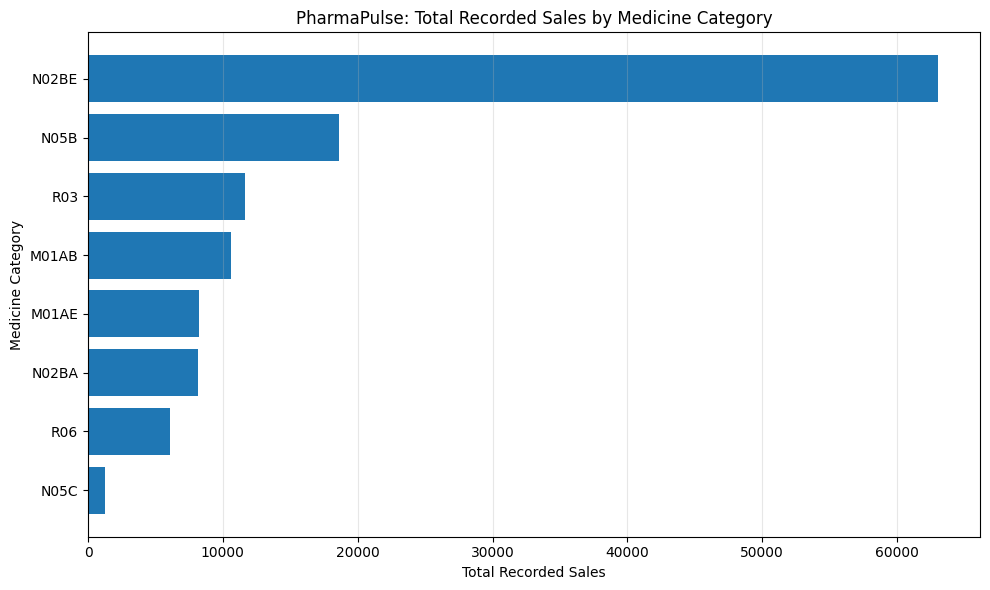

In [0]:
# create a category Contribution Chart
# Visualize total recorded sales by medicine category.
# A sorted horizontal bar chart makes category rankings and differences easier to compare.

import matplotlib.pyplot as plt

category_pd = category_summary.toPandas().sort_values(
    "Total_Sales",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    category_pd["Medicine_Category"],
    category_pd["Total_Sales"]
)

plt.title("PharmaPulse: Total Recorded Sales by Medicine Category")
plt.xlabel("Total Recorded Sales")
plt.ylabel("Medicine Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [0]:
# to build annual dashboard table 


# Build a dashboard-ready annual sales table with totals, category shares, and growth.
# This combines our previous analysis into one structured dataset for visualization.

from pyspark.sql import functions as F
from pyspark.sql.window import Window

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Calculate annual sales totals for each medicine category.
annual_dashboard = annual_category_sales.withColumn(
    "Total_Sales",
    sum(
        F.coalesce(F.col(c).cast("double"), F.lit(0.0))
        for c in medicine_columns
    )
)

# Calculate each category's share of the year's total sales.
for category in medicine_columns:
    annual_dashboard = annual_dashboard.withColumn(
        f"{category}_Share_Percent",
        F.round(
            F.col(category) / F.col("Total_Sales") * 100,
            2
        )
    )

# Compare total sales with the previous year.
year_window = Window.orderBy("Year")
annual_dashboard = annual_dashboard.withColumn(
    "Previous_Year_Total",
    F.lag("Total_Sales").over(year_window)
)

annual_dashboard = annual_dashboard.withColumn(
    "Total_Sales_YoY_Percent",
    F.round(
        (F.col("Total_Sales") - F.col("Previous_Year_Total"))
        / F.col("Previous_Year_Total") * 100,
        2
    )
)

# Keep the final table in chronological order.
annual_dashboard = annual_dashboard.orderBy("Year")

display(annual_dashboard)


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Year,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Total_Sales,M01AB_Share_Percent,M01AE_Share_Percent,N02BA_Share_Percent,N02BE_Share_Percent,N05B_Share_Percent,N05C_Share_Percent,R03_Share_Percent,R06_Share_Percent,Previous_Year_Total,Total_Sales_YoY_Percent
2014,1447.21,1257.1,1616.47,9274.38,4315.06,272.63,1255.0,800.49,20238.340000000004,7.15,6.21,7.99,45.83,21.32,1.35,6.2,3.96,null,null
2015,1895.62,1496.6,1608.63,11923.22,2965.0,159.0,1721.25,983.03,22752.35,8.33,6.58,7.07,52.4,13.03,0.7,7.57,4.32,20238.340000000004,12.42
2016,2107.28,1589.44,1655.22,13335.58,3138.33,207.0,2137.0,1065.07,25234.92,8.35,6.3,6.56,52.85,12.44,0.82,8.47,4.22,22752.35,10.91
2017,1846.62,1387.3,1288.3,9258.8,2555.54,180.33,1893.61,988.86,19399.360000000004,9.52,7.15,6.64,47.73,13.17,0.93,9.76,5.1,25234.92,-23.12
2018,1786.93,1389.66,1123.8,11230.92,3266.2,235.0,2655.25,1196.8,22884.56,7.81,6.07,4.91,49.08,14.27,1.03,11.6,5.23,19399.360000000004,17.97
2019,1517.27,1084.52,879.8,7982.49,2405.6,196.0,1946.71,1073.57,17085.96,8.88,6.35,5.15,46.72,14.08,1.15,11.39,6.28,22884.56,-25.34


In [0]:

# Save the prepared annual summary as a reusable Databricks table.
# This makes the dashboard dataset available for future SQL queries and visualizations.

(
    annual_dashboard
    .write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable("workspace.default.pharmapulse_annual_dashboard")
)

# Read the saved table back to verify that it was created successfully.
saved_dashboard = spark.table("workspace.default.pharmapulse_annual_dashboard")

display(saved_dashboard.orderBy("Year"))


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Year,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Total_Sales,M01AB_Share_Percent,M01AE_Share_Percent,N02BA_Share_Percent,N02BE_Share_Percent,N05B_Share_Percent,N05C_Share_Percent,R03_Share_Percent,R06_Share_Percent,Previous_Year_Total,Total_Sales_YoY_Percent
2014,1447.21,1257.1,1616.47,9274.38,4315.06,272.63,1255.0,800.49,20238.340000000004,7.15,6.21,7.99,45.83,21.32,1.35,6.2,3.96,null,null
2015,1895.62,1496.6,1608.63,11923.22,2965.0,159.0,1721.25,983.03,22752.35,8.33,6.58,7.07,52.4,13.03,0.7,7.57,4.32,20238.340000000004,12.42
2016,2107.28,1589.44,1655.22,13335.58,3138.33,207.0,2137.0,1065.07,25234.92,8.35,6.3,6.56,52.85,12.44,0.82,8.47,4.22,22752.35,10.91
2017,1846.62,1387.3,1288.3,9258.8,2555.54,180.33,1893.61,988.86,19399.360000000004,9.52,7.15,6.64,47.73,13.17,0.93,9.76,5.1,25234.92,-23.12
2018,1786.93,1389.66,1123.8,11230.92,3266.2,235.0,2655.25,1196.8,22884.56,7.81,6.07,4.91,49.08,14.27,1.03,11.6,5.23,19399.360000000004,17.97
2019,1517.27,1084.52,879.8,7982.49,2405.6,196.0,1946.71,1073.57,17085.96,8.88,6.35,5.15,46.72,14.08,1.15,11.39,6.28,22884.56,-25.34


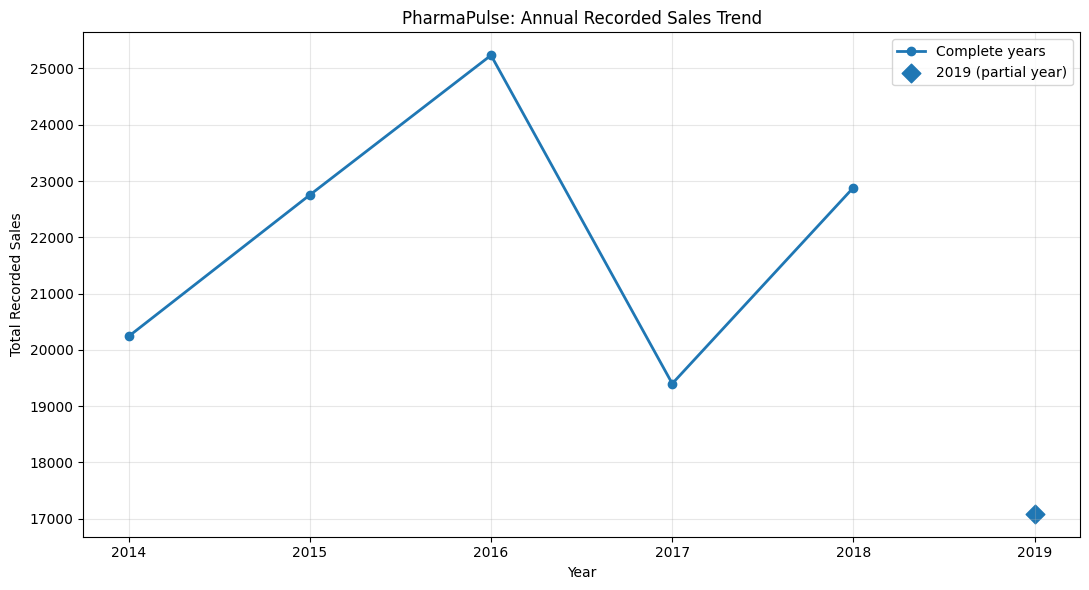

In [0]:
# create the annual sales chart 
# Visualize annual recorded sales to show the overall trend over time.
# We distinguish 2019 because the available data covers only part of that year.

import matplotlib.pyplot as plt

annual_pd = (
    spark.table("workspace.default.pharmapulse_annual_dashboard")
    .select("Year", "Total_Sales")
    .orderBy("Year")
    .toPandas()
)

# Separate complete years from the partial 2019 period.
complete_years = annual_pd[annual_pd["Year"] < 2019]
partial_year = annual_pd[annual_pd["Year"] == 2019]

plt.figure(figsize=(11, 6))

plt.plot(
    complete_years["Year"],
    complete_years["Total_Sales"],
    marker="o",
    linewidth=2,
    label="Complete years"
)

# Show partial 2019 data separately to avoid implying a full-year comparison.
if not partial_year.empty:
    plt.scatter(
        partial_year["Year"],
        partial_year["Total_Sales"],
        marker="D",
        s=90,
        label="2019 (partial year)"
    )

plt.title("PharmaPulse: Annual Recorded Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Recorded Sales")
plt.xticks(annual_pd["Year"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


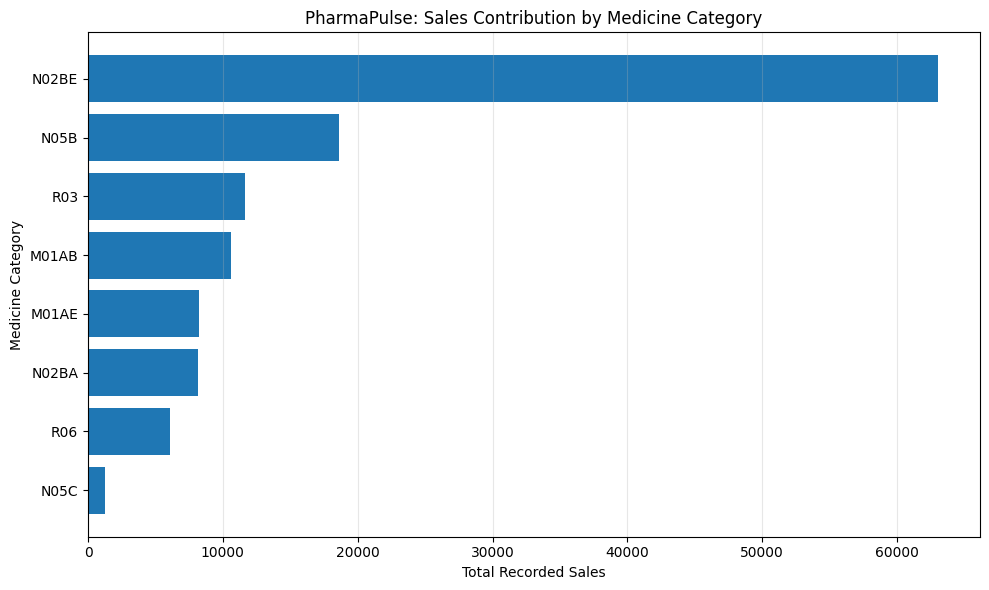

In [0]:
# Category Distribution Chart 
# Visualize total recorded sales by medicine category across the full dataset.
# This helps identify the categories that contribute most to overall sales.

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

medicine_columns = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

# Calculate total recorded sales for each category from the hourly data.
category_totals = sales_hourly.agg(
    *[
        F.sum(
            F.coalesce(F.col(c).cast("double"), F.lit(0.0))
        ).alias(c)
        for c in medicine_columns
    ]
)

# Convert the category totals into a format suitable for plotting.
category_pd = category_totals.toPandas().melt(
    var_name="Medicine_Category",
    value_name="Total_Sales"
).sort_values("Total_Sales", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(
    category_pd["Medicine_Category"],
    category_pd["Total_Sales"]
)

plt.title("PharmaPulse: Sales Contribution by Medicine Category")
plt.xlabel("Total Recorded Sales")
plt.ylabel("Medicine Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


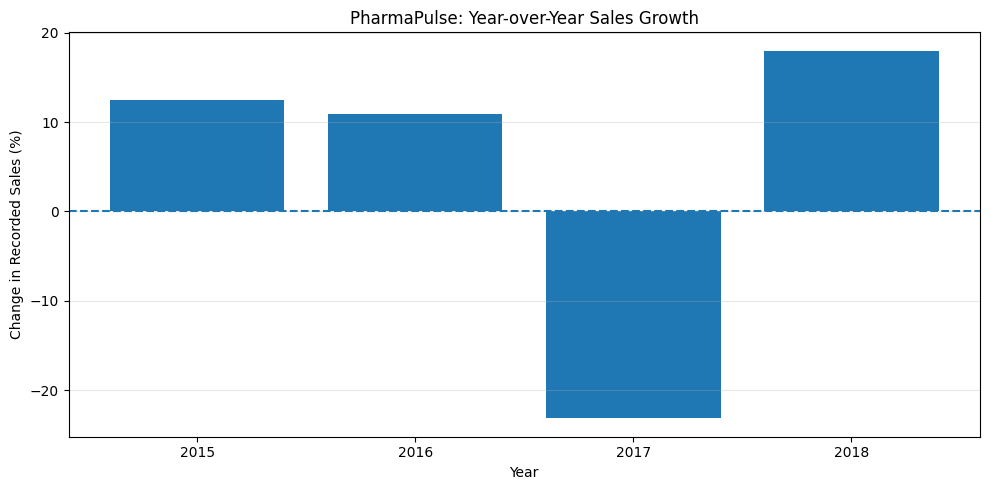

In [0]:
# visualize the annual Sales Growth
# Visualize year-over-year changes in total recorded sales.
# We exclude 2019 because its partial-year total cannot be compared fairly with full years.

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

growth_pd = (
    spark.table("workspace.default.pharmapulse_annual_dashboard")
    .filter(F.col("Year").between(2015, 2018))
    .select("Year", "Total_Sales_YoY_Percent")
    .orderBy("Year")
    .toPandas()
)

plt.figure(figsize=(10, 5))

plt.bar(
    growth_pd["Year"].astype(str),
    growth_pd["Total_Sales_YoY_Percent"]
)

plt.axhline(y=0, linestyle="--")
plt.title("PharmaPulse: Year-over-Year Sales Growth")
plt.xlabel("Year")
plt.ylabel("Change in Recorded Sales (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
